# FrameFill – GOES-19 C13 interpolation (Kaggle-safe)
Run cells top to bottom. **Set Accelerator (GPU T4) and Internet ON *before* running** – changing them restarts the session and wipes `/kaggle/working`.
Every stage skips work whose output file already exists.

In [1]:
# CELL 1 - environment
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
import sys, subprocess, importlib
for mod, pipname in [("s3fs","s3fs"),("h5netcdf","h5netcdf"),("xarray","xarray"),("cv2","opencv-python-headless"),("skimage","scikit-image")]:
    try: importlib.import_module(mod)
    except ImportError:
        subprocess.run([sys.executable,"-m","pip","install","-q",pipname])
import torch
print("python", sys.version.split()[0], "| torch", torch.__version__, "| cuda", torch.cuda.is_available())
os.makedirs("/kaggle/working", exist_ok=True)

python 3.13.15 | torch 2.11.0+cu128 | cuda True


In [2]:
# CELL 2 - download GOES-19 C13 crops (skipped if already saved)
import s3fs, xarray as xr, numpy as np, re, os
from concurrent.futures import ThreadPoolExecutor
fs = s3fs.S3FileSystem(anon=True)
Y0, X0, S = 2400, 2400, 512

def parse_time(key):
    m = re.search(r"_s(\d{4})(\d{3})(\d{2})(\d{2})", key)
    y, d, hh, mm = map(int, m.groups())
    return np.datetime64(f"{y}-01-01") + np.timedelta64(d-1,"D") + np.timedelta64(hh*60+mm,"m")

def load_crop(key):
    with fs.open(key) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", mask_and_scale=True)
        arr = ds["CMI"].isel(y=slice(Y0,Y0+S), x=slice(X0,X0+S)).values.astype("float32")
        ds.close()
        return arr

def safe(k):
    try: return load_crop(k), parse_time(k)
    except Exception as e:
        print("skip", k.split("/")[-1], repr(e)[:100]); return None

def grab(day, name):
    out_path = f"/kaggle/working/{name}.npz"
    if os.path.exists(out_path):
        print(name, "exists, skipping"); return
    files = sorted(f for h in fs.ls(day) for f in fs.ls(h) if "C13" in f and f.endswith(".nc"))
    print(day, len(files), "files")
    with ThreadPoolExecutor(4) as ex:
        out = [r for r in ex.map(safe, files) if r is not None]
    fr = np.stack([r[0] for r in out]); tm = np.array([r[1] for r in out])
    np.savez_compressed(out_path, frames=fr, times=tm)
    print(name, fr.shape, np.nanmin(fr), np.nanmax(fr))

grab("noaa-goes19/ABI-L2-CMIPF/2026/295", "crops_dayA")
grab("noaa-goes19/ABI-L2-CMIPF/2026/292", "crops_dayB")

noaa-goes19/ABI-L2-CMIPF/2026/295 144 files
crops_dayA (144, 512, 512) 187.5766 316.0755
noaa-goes19/ABI-L2-CMIPF/2026/292 144 files
crops_dayB (144, 512, 512) 185.54865 316.81293


In [3]:
# CELL 3 - triplets, metrics, baselines B0/B1
import cv2, pandas as pd
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter
LO, HI = 180.0, 330.0

def build_triplets(frames, times):
    t = []
    for i in range(len(times)-2):
        if (times[i+2]-times[i]) == np.timedelta64(20,"m") and max(np.isnan(frames[j]).mean() for j in (i,i+1,i+2)) < 0.2:
            t.append((i, i+1, i+2))
    return t

d = np.load("/kaggle/working/crops_dayA.npz"); frames, times = d["frames"], d["times"]
triplets = build_triplets(frames, times)
dB = np.load("/kaggle/working/crops_dayB.npz"); framesB, timesB = dB["frames"], dB["times"]
tripletsB = build_triplets(framesB, timesB)
print("Day A triplets:", len(triplets), "| Day B triplets:", len(tripletsB))
np.save("/kaggle/working/triplets_A.npy", np.array(triplets))
np.save("/kaggle/working/triplets_B.npy", np.array(tripletsB))

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO),0,1)*255).astype("uint8")
def b0(f0, f1): return 0.5*f0 + 0.5*f1

dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1
    out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out

def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D)
    n = lambda x: np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO),0,1)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2,1e-9)),
                SSIM=ssim(n(P), n(G), data_range=1.0, win_size=7),
                MAE_dyn=mae_d, RMSE_dyn=rmse_d, dyn_frac=D.mean())

def eval_engine(engine, fr, trips, name):
    rows = [metrics(engine(fr[a], fr[b]), fr[m], fr[a], fr[b]) for a,m,b in trips]
    print(name, len(rows)); return pd.DataFrame(rows)

def eval_file(path, fr, trips):
    P = np.load(path)["preds"]
    return pd.DataFrame([metrics(P[k], fr[m], fr[a], fr[b]) for k,(a,m,b) in enumerate(trips[:len(P)])])

base = {"B0": eval_engine(b0, frames, triplets, "B0"),
        "B1": eval_engine(b1, frames, triplets, "B1")}
tab0 = pd.DataFrame({k: v.mean() for k, v in base.items()}).T.round(3)
print(tab0); tab0.to_csv("/kaggle/working/dayA_baselines.csv")

Day A triplets: 142 | Day B triplets: 142
B0 142
B1 142
      MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0  2.085  3.314  33.318  0.867    2.965     4.193      0.56
B1  1.310  2.042  37.383  0.944    1.746     2.500      0.56


In [4]:
# CELL 4 - prepare a writable RIFE package (copy code + weights, stub training-only loss)
import shutil, os
SRC_REPO = "/kaggle/input/datasets/arpitdeosthale/practical-rife-code/Practical-RIFE"
SRC_WTS  = "/kaggle/input/datasets/arpitdeosthale/rife-weights/RIFEv4.22"
PKG = "/kaggle/working/rife_pkg"
assert os.path.isdir(SRC_REPO + "/model"), "RIFE code dataset not attached"
assert os.path.isfile(SRC_WTS + "/train_log/flownet.pkl"), "RIFE weights dataset not attached"
ign = shutil.ignore_patterns("__pycache__", "*.pyc")
shutil.copytree(SRC_REPO + "/model", PKG + "/model", ignore=ign, dirs_exist_ok=True)
shutil.copytree(SRC_WTS + "/train_log", PKG + "/train_log", ignore=ign, dirs_exist_ok=True)
for dname in ("model", "train_log"):
    open(f"{PKG}/{dname}/__init__.py", "a").close()
print(sorted(os.listdir(PKG + "/model")), sorted(os.listdir(PKG + "/train_log")))

['__init__.py', 'loss.py', 'pytorch_msssim', 'warplayer.py'] ['IFNet_HDv3.py', 'RIFE_HDv3.py', '__init__.py', 'flownet.pkl', 'refine.py']


In [5]:
%%writefile /kaggle/working/rife_run.py
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
import sys, argparse, types, traceback
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F

p = argparse.ArgumentParser()
p.add_argument("--data", default="/kaggle/working/crops_dayA.npz")
p.add_argument("--trips", default="/kaggle/working/triplets_A.npy")
p.add_argument("--out", required=True)
p.add_argument("--mode", default="fixed")      # fixed | naive
p.add_argument("--scale", type=float, default=1.0)
p.add_argument("--invert", type=int, default=0)
p.add_argument("--limit", type=int, default=0)
a = p.parse_args()
PKG = "/kaggle/working/rife_pkg"

try:
    torch.set_num_threads(4)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    sys.path.insert(0, PKG)

    import model.warplayer
    try:
        import model.loss
    except Exception as e:
        print("stubbing model.loss:", repr(e), flush=True)
        stub = types.ModuleType("model.loss")
        class _Noop(nn.Module):
            def __init__(self, *args, **kw): super().__init__()
            def forward(self, *args, **kw): return torch.zeros(1)
        for n in ("EPE", "SOBEL", "Ternary", "VGGPerceptualLoss", "MeanShift"):
            setattr(stub, n, _Noop)
        sys.modules["model.loss"] = stub
        model.loss = stub

    from train_log.RIFE_HDv3 import Model
    net = Model()
    net.load_model(PKG + "/train_log", -1)
    net.eval(); net.device()
    print("model ready on", dev, flush=True)

    LO, HI = 180.0, 330.0
    frames = np.load(a.data)["frames"]; trips = np.load(a.trips)
    if a.limit: trips = trips[:a.limit]

    def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
    PAD = max(128, int(128 / a.scale))
    def prep(x, lo, hi):
        x = np.clip((fill(x) - lo) / (hi - lo), 0, 1)
        t = torch.from_numpy(x)[None, None].repeat(1, 3, 1, 1).float().to(dev)
        h, w = t.shape[-2:]
        ph, pw = ((h - 1) // PAD + 1) * PAD, ((w - 1) // PAD + 1) * PAD
        return F.pad(t, (0, pw - w, 0, ph - h), mode="replicate"), h, w

    preds = []
    with torch.no_grad():
        for i, (ia, im, ib) in enumerate(trips):
            f0, f1 = frames[ia], frames[ib]
            if a.mode == "fixed":
                lo0 = lo1 = LO; hi0 = hi1 = HI
            else:
                lo0, hi0 = np.nanmin(f0), np.nanmax(f0); lo1, hi1 = np.nanmin(f1), np.nanmax(f1)
            x0, h, w = prep(f0, lo0, hi0); x1, _, _ = prep(f1, lo1, hi1)
            if a.invert: x0, x1 = 1 - x0, 1 - x1
            out = net.inference(x0, x1, 0.5, a.scale)
            if a.invert: out = 1 - out
            y = out.mean(1)[0, :h, :w].clamp(0, 1).cpu().numpy()
            lo, hi = (lo0 + lo1) / 2, (hi0 + hi1) / 2
            bt = y * (hi - lo) + lo
            bt = np.clip(bt, min(np.nanmin(f0), np.nanmin(f1)) - 5, max(np.nanmax(f0), np.nanmax(f1)) + 5)
            bt[np.isnan(f0) | np.isnan(f1)] = np.nan
            preds.append(bt.astype("float32"))
            if i % 20 == 0: print("frame", i, flush=True)
    np.savez_compressed(a.out, preds=np.stack(preds), trips=trips)
    print("done", len(preds), flush=True)
except Exception:
    traceback.print_exc()
    sys.exit(1)

Writing /kaggle/working/rife_run.py


In [6]:
# CELL 6 - runner that cannot kill the notebook
import subprocess, sys
def run_rife(*args):
    r = subprocess.run([sys.executable, "-X", "faulthandler", "/kaggle/working/rife_run.py", *args],
                       capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-40:]))
    print("exit code:", r.returncode)
    return r.returncode == 0

ok = run_rife("--out", "/kaggle/working/p_test.npz", "--limit", "3")   # smoke test

model ready on cuda
frame 0
done 3
exit code: 0


In [7]:
# CELL 7 - full RIFE runs (only if smoke test passed; skips finished outputs)
import os
if not ok:
    print("Smoke test failed - fix that first (see traceback above).")
else:
    if not os.path.exists("/kaggle/working/A_B3.npz"):
        run_rife("--out", "/kaggle/working/A_B3.npz", "--mode", "fixed")
    if not os.path.exists("/kaggle/working/A_B2.npz"):
        run_rife("--out", "/kaggle/working/A_B2.npz", "--mode", "naive")

model ready on cuda
frame 0
frame 20
frame 40
frame 60
frame 80
frame 100
frame 120
frame 140
done 142
exit code: 0
model ready on cuda
frame 0
frame 20
frame 40
frame 60
frame 80
frame 100
frame 120
frame 140
done 142
exit code: 0


In [8]:
# CELL 8 - results table
res = dict(base)
for label, path in [("B2 naive","/kaggle/working/A_B2.npz"), ("B3 fixed","/kaggle/working/A_B3.npz")]:
    if os.path.exists(path):
        res[label] = eval_file(path, frames, triplets)
tab = pd.DataFrame({k: v.mean() for k, v in res.items()}).T.round(3)
print(tab); tab.to_csv("/kaggle/working/dayA_results.csv")

            MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0        2.085  3.314  33.318  0.867    2.965     4.193      0.56
B1        1.310  2.042  37.383  0.944    1.746     2.500      0.56
B2 naive  1.347  2.110  37.093  0.942    1.793     2.585      0.56
B3 fixed  1.338  2.096  37.150  0.942    1.782     2.567      0.56


In [9]:
import os, glob, shutil
os.makedirs("/kaggle/working", exist_ok=True)
names = ["crops_dayA.npz", "crops_dayB.npz", "triplets_A.npy", "triplets_B.npy",
         "A_B3.npz", "A_B2.npz", "dayA_baselines.csv", "dayA_results.csv"]
for n in names:
    dst = f"/kaggle/working/{n}"
    if os.path.exists(dst):
        continue
    hits = glob.glob(f"/kaggle/input/**/{n}", recursive=True)
    if hits:
        shutil.copy(hits[0], dst)
        print("restored", n, "<-", hits[0])
    else:
        print("NOT FOUND", n)

In [10]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np, pandas as pd, cv2
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter

LO, HI = 180.0, 330.0
W = "/kaggle/working"
frames = np.load(f"{W}/crops_dayA.npz")["frames"]
triplets = np.load(f"{W}/triplets_A.npy")

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO),0,1)*255).astype("uint8")
def b0(f0, f1): return 0.5*f0 + 0.5*f1

dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1
    out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out

def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D)
    n = lambda x: np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO),0,1)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2,1e-9)),
                SSIM=ssim(n(P), n(G), data_range=1.0, win_size=7),
                MAE_dyn=mae_d, RMSE_dyn=rmse_d, dyn_frac=D.mean())

def eval_engine(engine):
    return pd.DataFrame([metrics(engine(frames[a], frames[b]), frames[m], frames[a], frames[b]) for a,m,b in triplets])
def eval_file(path):
    P = np.load(path)["preds"]
    return pd.DataFrame([metrics(P[k], frames[m], frames[a], frames[b]) for k,(a,m,b) in enumerate(triplets[:len(P)])])

res = {"B0": eval_engine(b0), "B1": eval_engine(b1),
       "B2 naive": eval_file(f"{W}/A_B2.npz"), "B3 fixed": eval_file(f"{W}/A_B3.npz")}
tab = pd.DataFrame({k: v.mean() for k, v in res.items()}).T.round(3)
print(tab)
tab.to_csv(f"{W}/dayA_results.csv")

# paired bootstrap over triplets: positive diff means the first engine has higher error
def boot(a, b, col="RMSE_dyn", n=1000, seed=42):
    d = (res[a][col] - res[b][col]).dropna().values
    rng = np.random.default_rng(seed)
    means = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    lo, hi = np.percentile(means, [2.5, 97.5])
    print(f"{a} - {b} on {col}: mean diff {d.mean():+.3f} K, 95% CI [{lo:+.3f}, {hi:+.3f}], N={len(d)}")

boot("B3 fixed", "B1")      # does RIFE differ from classical flow?
boot("B2 naive", "B3 fixed") # does fixed-range normalisation help?
boot("B0", "B1")             # sanity: flow vs blend

            MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0        2.085  3.314  33.318  0.867    2.965     4.193      0.56
B1        1.310  2.042  37.383  0.944    1.746     2.500      0.56
B2 naive  1.347  2.110  37.093  0.942    1.793     2.585      0.56
B3 fixed  1.338  2.096  37.150  0.942    1.782     2.567      0.56
B3 fixed - B1 on RMSE_dyn: mean diff +0.067 K, 95% CI [+0.062, +0.072], N=142
B2 naive - B3 fixed on RMSE_dyn: mean diff +0.018 K, 95% CI [+0.016, +0.021], N=142
B0 - B1 on RMSE_dyn: mean diff +1.694 K, 95% CI [+1.573, +1.814], N=142


In [11]:
import os, shutil, subprocess, sys
W = "/kaggle/working"
SRC = "/kaggle/input/notebooks/arpitdeosthale/be-project"

# restore the runner and the RIFE package from your saved output
shutil.copytree(f"{SRC}/rife_pkg", f"{W}/rife_pkg", dirs_exist_ok=True)
shutil.copy(f"{SRC}/rife_run.py", f"{W}/rife_run.py")
print("package:", sorted(os.listdir(f"{W}/rife_pkg")),
      "| weights:", os.path.exists(f"{W}/rife_pkg/train_log/flownet.pkl"))

def run_rife(*args):
    r = subprocess.run([sys.executable, "-X", "faulthandler", f"{W}/rife_run.py", *args],
                       capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-8:]))
    return r.returncode == 0

dayB = ["--data", f"{W}/crops_dayB.npz", "--trips", f"{W}/triplets_B.npy"]
jobs = [("A_B3_s05", ["--scale", "0.5"]),
        ("A_B3_inv", ["--invert", "1"]),
        ("B_B3",     dayB),
        ("B_B2",     dayB + ["--mode", "naive"])]
for name, extra in jobs:
    out = f"{W}/{name}.npz"
    if os.path.exists(out):
        print(name, "exists, skipping"); continue
    print(name, "->", "ok" if run_rife("--out", out, *extra) else "FAILED")

package: ['model', 'train_log'] | weights: True
frame 20
frame 40
frame 60
frame 80
frame 100
frame 120
frame 140
done 142
A_B3_s05 -> ok
frame 20
frame 40
frame 60
frame 80
frame 100
frame 120
frame 140
done 142
A_B3_inv -> ok
frame 20
frame 40
frame 60
frame 80
frame 100
frame 120
frame 140
done 142
B_B3 -> ok
frame 20
frame 40
frame 60
frame 80
frame 100
frame 120
frame 140
done 142
B_B2 -> ok


In [12]:
framesB = np.load(f"{W}/crops_dayB.npz")["frames"]
tripsB  = np.load(f"{W}/triplets_B.npy")

def eval_eng(engine, fr, trips):
    return pd.DataFrame([metrics(engine(fr[a], fr[b]), fr[m], fr[a], fr[b]) for a,m,b in trips])
def eval_f(path, fr, trips):
    P = np.load(path)["preds"]
    return pd.DataFrame([metrics(P[k], fr[m], fr[a], fr[b]) for k,(a,m,b) in enumerate(trips[:len(P)])])
def boot2(R, a, b, col="RMSE_dyn", n=1000, seed=42):
    d = (R[a][col] - R[b][col]).dropna().values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    lo, hi = np.percentile(m, [2.5, 97.5])
    print(f"  {a} - {b}: {d.mean():+.3f} K, 95% CI [{lo:+.3f}, {hi:+.3f}], N={len(d)}")

# ---- Day B hold-out ----
resB = {"B0": eval_eng(b0, framesB, tripsB), "B1": eval_eng(b1, framesB, tripsB),
        "B2 naive": eval_f(f"{W}/B_B2.npz", framesB, tripsB),
        "B3 fixed": eval_f(f"{W}/B_B3.npz", framesB, tripsB)}
tabB = pd.DataFrame({k: v.mean() for k, v in resB.items()}).T.round(3)
print("=== Day B (held-out) ===\n", tabB)
boot2(resB, "B3 fixed", "B1"); boot2(resB, "B0", "B1"); boot2(resB, "B2 naive", "B3 fixed")
tabB.to_csv(f"{W}/dayB_results.csv")

# ---- RIFE ablations on Day A ----
abl = {"B1": res["B1"], "B3 fixed": res["B3 fixed"],
       "B3 scale0.5": eval_f(f"{W}/A_B3_s05.npz", frames, triplets),
       "B3 invert":   eval_f(f"{W}/A_B3_inv.npz", frames, triplets)}
tabA = pd.DataFrame({k: v.mean() for k, v in abl.items()}).T.round(3)
print("\n=== Day A ablations ===\n", tabA)
boot2(abl, "B3 scale0.5", "B3 fixed"); boot2(abl, "B3 invert", "B3 fixed"); boot2(abl, "B3 scale0.5", "B1")
tabA.to_csv(f"{W}/dayA_ablations.csv")

# ---- error vs displacement (Day A): does RIFE win on fast motion? ----
def mean_disp(f0, f1):
    fl = dis.calc(to8(f0), to8(f1), None)
    return float(np.hypot(fl[...,0], fl[...,1]).mean())
disp = np.array([mean_disp(frames[a], frames[b]) for a,m,b in triplets])
bins = pd.qcut(disp, 3, labels=["slow", "medium", "fast"])
rows = {k: pd.Series(abl[k]["RMSE_dyn"].values[:len(disp)]).groupby(bins).mean()
        for k in ["B1", "B3 fixed", "B3 scale0.5"]}
print("\n=== RMSE_dyn (K) by motion tercile ===")
print(pd.DataFrame(rows).round(3))
print("mean displacement per tercile (px / 20 min):",
      pd.Series(disp).groupby(bins).mean().round(2).to_dict())

=== Day B (held-out) ===
             MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0        1.708  2.913  34.472  0.906    2.753     4.033     0.474
B1        1.213  2.005  37.713  0.951    1.842     2.693     0.474
B2 naive  1.241  2.052  37.513  0.949    1.873     2.748     0.474
B3 fixed  1.237  2.044  37.546  0.949    1.867     2.736     0.474
  B3 fixed - B1: +0.044 K, 95% CI [+0.036, +0.051], N=142
  B0 - B1: +1.340 K, 95% CI [+1.306, +1.378], N=142
  B2 naive - B3 fixed: +0.011 K, 95% CI [+0.009, +0.014], N=142

=== Day A ablations ===
                MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B1           1.310  2.042  37.383  0.944    1.746     2.500      0.56
B3 fixed     1.338  2.096  37.150  0.942    1.782     2.567      0.56
B3 scale0.5  1.501  2.336  36.203  0.929    2.010     2.872      0.56
B3 invert    1.338  2.098  37.145  0.942    1.783     2.569      0.56
  B3 scale0.5 - B3 fixed: +0.306 K, 95% CI [+0.297, +0.314], N=142
  B3 invert - B3 fixed

/tmp/ipykernel_22/3827578900.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rows = {k: pd.Series(abl[k]["RMSE_dyn"].values[:len(disp)]).groupby(bins).mean()
/tmp/ipykernel_22/3827578900.py:45: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pd.Series(disp).groupby(bins).mean().round(2).to_dict())


In [13]:
import os, subprocess, sys
W = "/kaggle/working"
assert os.path.exists(f"{W}/rife_run.py") and os.path.isdir(f"{W}/rife_pkg"), "rerun the restore cell first"

def run_rife(*args):
    r = subprocess.run([sys.executable, "-X", "faulthandler", f"{W}/rife_run.py", *args],
                       capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-4:]))
    return r.returncode == 0

dayB = ["--data", f"{W}/crops_dayB.npz", "--trips", f"{W}/triplets_B.npy"]
jobs = []
for s in ("1.5", "2.0"):
    tag = s.replace(".", "")
    jobs.append((f"A_B3_s{tag}", ["--scale", s]))
    jobs.append((f"B_B3_s{tag}", dayB + ["--scale", s]))

for name, extra in jobs:
    out = f"{W}/{name}.npz"
    if os.path.exists(out):
        print(name, "exists, skipping"); continue
    print(name, "->", "ok" if run_rife("--out", out, *extra) else "FAILED")

frame 100
frame 120
frame 140
done 142
A_B3_s15 -> ok
frame 100
frame 120
frame 140
done 142
B_B3_s15 -> ok
frame 100
frame 120
frame 140
done 142
A_B3_s20 -> ok
frame 100
frame 120
frame 140
done 142
B_B3_s20 -> ok


In [14]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np, pandas as pd, cv2
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter

W = "/kaggle/working"
LO, HI = 180.0, 330.0
data = {"A": (np.load(f"{W}/crops_dayA.npz")["frames"], np.load(f"{W}/triplets_A.npy")),
        "B": (np.load(f"{W}/crops_dayB.npz")["frames"], np.load(f"{W}/triplets_B.npy"))}

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO),0,1)*255).astype("uint8")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1
    out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out

def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D)
    n = lambda x: np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO),0,1)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2,1e-9)),
                SSIM=ssim(n(P), n(G), data_range=1.0, win_size=7),
                MAE_dyn=mae_d, RMSE_dyn=rmse_d, dyn_frac=D.mean())

def score(P, fr, trips):
    return pd.DataFrame([metrics(P[k], fr[m], fr[a], fr[b]) for k,(a,m,b) in enumerate(trips[:len(P)])])

def boot2(R, a, b, col="RMSE_dyn", n=1000, seed=42):
    d = (R[a][col] - R[b][col]).dropna().values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    lo, hi = np.percentile(m, [2.5, 97.5])
    print(f"  {a} - {b}: {d.mean():+.3f} K, 95% CI [{lo:+.3f}, {hi:+.3f}], N={len(d)}")

def rife_file(day, tag):
    name = {"A": {"1.0": "A_B3", "1.5": "A_B3_s15", "2.0": "A_B3_s20"},
            "B": {"1.0": "B_B3", "1.5": "B_B3_s15", "2.0": "B_B3_s20"}}[day][tag]
    return np.load(f"{W}/{name}.npz")["preds"]

for day in ("A", "B"):
    fr, trips = data[day]
    P1 = np.stack([b1(fr[a], fr[b]) for a,m,b in trips])
    R = {"B1": score(P1, fr, trips)}
    preds = {t: rife_file(day, t) for t in ("1.0", "1.5", "2.0")}
    for t, P in preds.items():
        R[f"B3 s{t}"] = score(P, fr, trips)
    for t in ("1.0", "2.0"):
        R[f"blend B1+B3 s{t}"] = score(0.5*P1 + 0.5*preds[t], fr, trips)
    tab = pd.DataFrame({k: v.mean() for k, v in R.items()}).T.round(3)
    print(f"\n=== Day {day} ===\n", tab[["MAE","RMSE","SSIM","MAE_dyn","RMSE_dyn"]])
    tab.to_csv(f"{W}/day{day}_scale_blend.csv")
    best_rife = min(("B3 s1.0","B3 s1.5","B3 s2.0"), key=lambda k: R[k]["RMSE_dyn"].mean())
    best_blend = min(("blend B1+B3 s1.0","blend B1+B3 s2.0"), key=lambda k: R[k]["RMSE_dyn"].mean())
    print(f"best RIFE: {best_rife} | best blend: {best_blend}")
    boot2(R, best_rife, "B1"); boot2(R, best_blend, "B1")


=== Day A ===
                     MAE   RMSE   SSIM  MAE_dyn  RMSE_dyn
B1                1.310  2.042  0.944    1.746     2.500
B3 s1.0           1.338  2.096  0.942    1.782     2.567
B3 s1.5           1.297  2.036  0.945    1.726     2.490
B3 s2.0           1.299  2.035  0.946    1.732     2.491
blend B1+B3 s1.0  1.277  1.991  0.947    1.699     2.435
blend B1+B3 s2.0  1.263  1.968  0.948    1.683     2.407
best RIFE: B3 s1.5 | best blend: blend B1+B3 s2.0
  B3 s1.5 - B1: -0.010 K, 95% CI [-0.016, -0.004], N=142
  blend B1+B3 s2.0 - B1: -0.092 K, 95% CI [-0.100, -0.086], N=142

=== Day B ===
                     MAE   RMSE   SSIM  MAE_dyn  RMSE_dyn
B1                1.213  2.005  0.951    1.842     2.693
B3 s1.0           1.237  2.044  0.949    1.867     2.736
B3 s1.5           1.191  1.966  0.952    1.795     2.627
B3 s2.0           1.192  1.959  0.953    1.799     2.619
blend B1+B3 s1.0  1.181  1.943  0.953    1.784     2.599
blend B1+B3 s2.0  1.166  1.913  0.955    1.763     2.5

In [15]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np, pandas as pd, cv2

W = "/kaggle/working"
LO, HI = 180.0, 330.0
data = {"A": (np.load(f"{W}/crops_dayA.npz")["frames"], np.load(f"{W}/triplets_A.npy")),
        "B": (np.load(f"{W}/crops_dayB.npz")["frames"], np.load(f"{W}/triplets_B.npy"))}

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO),0,1)*255).astype("uint8")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b0(f0, f1): return 0.5*f0 + 0.5*f1
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1
    out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out

# ---- sharpness metrics ----
def grad_mag(x):
    gx = cv2.Sobel(x, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(x, cv2.CV_32F, 0, 1, ksize=3)
    return np.hypot(gx, gy)

_hann = None
def hf_power(x):
    global _hann
    n = x.shape[0]
    if _hann is None or _hann.shape[0] != n:
        _hann = np.outer(np.hanning(n), np.hanning(n)).astype("float32")
    x = (x - x.mean()) * _hann
    F = np.fft.fftshift(np.fft.fft2(x))
    P = np.abs(F)**2
    yy, xx = np.indices(P.shape); c = n//2
    r = np.hypot(yy-c, xx-c) / (n/2)
    return P[r >= 0.75].sum()          # top 25% of wavenumbers

def sharp_metrics(P, G):
    V = np.isfinite(P) & np.isfinite(G)
    ref = np.nanmean(G)
    Pf = np.where(V, P, ref).astype("float32"); Gf = np.where(V, G, ref).astype("float32")
    gc = np.corrcoef(grad_mag(Pf).ravel(), grad_mag(Gf).ravel())[0, 1]
    return dict(grad_corr=gc,
                grad_mag_ratio=grad_mag(Pf)[V].mean() / grad_mag(Gf)[V].mean(),
                hf_ratio=hf_power(Pf) / hf_power(Gf),
                bias_K=(P - G)[V].mean())

def rife(day, tag):
    return np.load(f"{W}/{ {'A': 'A_B3_s20', 'B': 'B_B3_s20'}[day] }.npz")["preds"]

for day in ("A", "B"):
    fr, trips = data[day]
    G  = np.stack([fr[m] for a, m, b in trips])
    P0 = np.stack([b0(fr[a], fr[b]) for a, m, b in trips])
    P1 = np.stack([b1(fr[a], fr[b]) for a, m, b in trips])
    P3 = rife(day, "s20")[:len(trips)]
    PB = 0.5*P1 + 0.5*P3
    engines = {"B0 average": P0, "B1 DIS flow": P1, "B3 RIFE s2.0": P3, "Blend B1+B3": PB}
    rows = {k: pd.DataFrame([sharp_metrics(P[i], G[i]) for i in range(len(G))]).mean()
            for k, P in engines.items()}
    print(f"\n=== Day {day}: sharpness vs observed frame (1.0 = as sharp as the truth) ===")
    print(pd.DataFrame(rows).T.round(3))


=== Day A: sharpness vs observed frame (1.0 = as sharp as the truth) ===
              grad_corr  grad_mag_ratio  hf_ratio  bias_K
B0 average        0.751           0.819     0.522  -0.002
B1 DIS flow       0.901           0.854     0.191  -0.010
B3 RIFE s2.0      0.906           0.879     0.317   0.029
Blend B1+B3       0.909           0.857     0.193   0.010

=== Day B: sharpness vs observed frame (1.0 = as sharp as the truth) ===
              grad_corr  grad_mag_ratio  hf_ratio  bias_K
B0 average        0.805           0.846     0.513   0.001
B1 DIS flow       0.914           0.865     0.185  -0.003
B3 RIFE s2.0      0.922           0.889     0.321   0.041
Blend B1+B3       0.923           0.867     0.193   0.019


In [16]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import numpy as np, xarray as xr, cv2

W = "/kaggle/working"
LO, HI = 180.0, 330.0
d = np.load(f"{W}/crops_dayA.npz"); frames, times = d["frames"], d["times"]
trips = np.load(f"{W}/triplets_A.npy")
P3 = np.load(f"{W}/A_B3_s20.npz")["preds"]          # RIFE scale 2.0, one prediction per triplet
row = {int(a): k for k, (a, m, b) in enumerate(trips)}   # first-frame index -> prediction row

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO),0,1)*255).astype("uint8")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1
    out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out

# observed frames 20 min apart: pairs (i, i+2), (i+2, i+4), ... each needs a triplet starting at its first frame
def run_from(s, max_pairs=36):
    pairs, cur = [], s
    while cur in row and len(pairs) < max_pairs:
        pairs.append(cur); cur += 2
    return pairs
best = max((run_from(s) for s in sorted(row)), key=len)
print("20-min pairs in the sequence:", len(best), "| first observed frame index:", best[0])

seq, ftype, ifrac, tt = [], [], [], []
for i in best:
    seq.append(frames[i]); ftype.append(0); ifrac.append(0.0); tt.append(times[i])
    mid = 0.5 * b1(frames[i], frames[i+2]) + 0.5 * P3[row[i]]
    seq.append(mid.astype("float32")); ftype.append(1); ifrac.append(0.5)
    tt.append(times[i] + np.timedelta64(10, "m"))
last = best[-1] + 2                                   # close the sequence with the final observed frame
seq.append(frames[last]); ftype.append(0); ifrac.append(0.0); tt.append(times[last])

ds = xr.Dataset(
    {"brightness_temperature": (("time", "y", "x"), np.stack(seq).astype("float32"),
        {"units": "K", "long_name": "ABI C13 brightness temperature (observed or interpolated)",
         "standard_name": "toa_brightness_temperature"}),
     "frame_type": (("time",), np.array(ftype, dtype="int8"),
        {"long_name": "0 = observed, 1 = SYNTHETIC interpolated", "flag_values": np.array([0, 1], dtype="int8"),
         "flag_meanings": "observed synthetic_interpolated"}),
     "interp_fraction": (("time",), np.array(ifrac, dtype="float32"),
        {"long_name": "temporal fraction between bracketing observed frames"})},
    coords={"time": np.array(tt, dtype="datetime64[ns]")},
    attrs={"title": "FrameFill temporal interpolation of GOES-19 ABI Channel 13",
           "warning": "Frames with frame_type=1 are SYNTHETIC model output, not observations. Do not use for retrievals.",
           "source": "NOAA GOES-19 ABI-L2-CMIPF C13 (public NOAA data, modified here)",
           "method": "50/50 blend of OpenCV DIS flow-warp and RIFE v4.22 (scale 2.0)",
           "bt_range_k": "180-330", "Conventions": "CF-1.8", "roi_pixels": "y=2400:2912, x=2400:2912"})

out = f"{W}/framefill_dayA_10min.nc"
try:
    ds.to_netcdf(out, engine="h5netcdf", encoding={"brightness_temperature": {"zlib": True, "complevel": 4}})
except Exception as e:
    print("compression failed, writing plain:", repr(e)[:80]); ds.to_netcdf(out, engine="h5netcdf")

chk = xr.open_dataset(out, engine="h5netcdf")
print(chk)
n_syn = int((chk.frame_type == 1).sum()); n_obs = int((chk.frame_type == 0).sum())
print(f"frames: {chk.sizes['time']} | observed: {n_obs} | synthetic: {n_syn} | size MB: {round(os.path.getsize(out)/1e6, 1)}")
dt = np.diff(chk.time.values).astype("timedelta64[m]").astype(int)
print("time step (min) unique:", sorted(set(dt)))
print("warning attr:", chk.attrs["warning"])

20-min pairs in the sequence: 36 | first observed frame index: 0
<xarray.Dataset> Size: 77MB
Dimensions:                 (time: 73, y: 512, x: 512)
Coordinates:
  * time                    (time) datetime64[ns] 584B 2026-10-22 ... 2026-10...
Dimensions without coordinates: y, x
Data variables:
    brightness_temperature  (time, y, x) float32 77MB ...
    frame_type              (time) int8 73B ...
    interp_fraction         (time) float32 292B ...
Attributes:
    title:        FrameFill temporal interpolation of GOES-19 ABI Channel 13
    source:       NOAA GOES-19 ABI-L2-CMIPF C13 (public NOAA data, modified h...
    method:       50/50 blend of OpenCV DIS flow-warp and RIFE v4.22 (scale 2.0)
    bt_range_k:   180-330
    Conventions:  CF-1.8
    roi_pixels:   y=2400:2912, x=2400:2912
frames: 73 | observed: 37 | synthetic: 36 | size MB: 48.6
time step (min) unique: [np.int64(10)]
warning attr: Frames with frame_type=1 are SYNTHETIC model output, not observations. Do not use for retri

saved /kaggle/working/framefill_compare.gif 10.4 MB


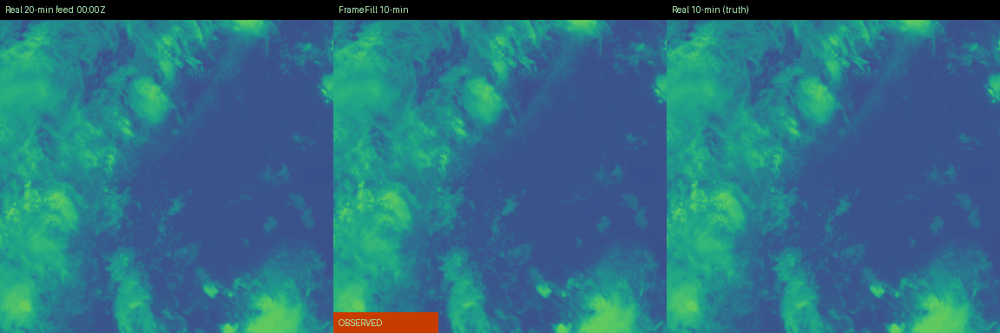

In [17]:
import numpy as np, xarray as xr
from PIL import Image, ImageDraw
from matplotlib import cm

W = "/kaggle/working"
LO, HI = 180.0, 330.0
ds = xr.open_dataset(f"{W}/framefill_dayA_10min.nc", engine="h5netcdf")
bt = ds.brightness_temperature.values
ftype = ds.frame_type.values
truth = np.load(f"{W}/crops_dayA.npz")["frames"][:len(bt)]     # nc frame n == observed frame n
times = ds.time.values.astype("datetime64[m]")

def colour(x, size=384):
    n = np.clip((np.nan_to_num(x, nan=LO) - LO) / (HI - LO), 0, 1)
    rgb = (cm.viridis(1 - n)[..., :3] * 255).astype("uint8")     # cold cloud = bright
    return Image.fromarray(rgb).resize((size, size), Image.BILINEAR)

def label(img, text, badge=None):
    d = ImageDraw.Draw(img)
    d.rectangle([0, 0, img.width, 22], fill=(0, 0, 0))
    d.text((6, 5), text, fill=(255, 255, 255))
    if badge:
        d.rectangle([0, img.height - 24, 120, img.height], fill=(200, 60, 0))
        d.text((6, img.height - 18), badge, fill=(255, 255, 255))
    return img

N = 36                                                           # first 6 hours
gif = []
for n in range(N):
    held = bt[2 * (n // 2)]                                      # last real 20-min frame
    p1 = label(colour(held), f"Real 20-min feed  {str(times[n])[11:16]}Z")
    syn = ftype[n] == 1
    p2 = label(colour(bt[n]), "FrameFill 10-min", "SYNTHETIC" if syn else "OBSERVED")
    p3 = label(colour(truth[n]), "Real 10-min (truth)")
    canvas = Image.new("RGB", (384 * 3, 384))
    for k, p in enumerate((p1, p2, p3)):
        canvas.paste(p, (384 * k, 0))
    gif.append(canvas)

out = f"{W}/framefill_compare.gif"
gif[0].save(out, save_all=True, append_images=gif[1:], duration=300, loop=0)
import os; print("saved", out, round(os.path.getsize(out) / 1e6, 1), "MB")
from IPython.display import Image as IPImage, display
display(IPImage(filename=out))

In [18]:
import os, subprocess, sys
import numpy as np
W = "/kaggle/working"
assert os.path.exists(f"{W}/rife_run.py") and os.path.isdir(f"{W}/rife_pkg"), "run the restore cell first"

def build_triplets_60(frames, times):
    t = []
    for i in range(len(times) - 6):
        if (times[i+6] - times[i]) == np.timedelta64(60, "m") and \
           max(np.isnan(frames[j]).mean() for j in (i, i+3, i+6)) < 0.2:
            t.append((i, i+3, i+6))
    return np.array(t)

for day in ("A", "B"):
    d = np.load(f"{W}/crops_day{day}.npz")
    tr = build_triplets_60(d["frames"], d["times"])
    np.save(f"{W}/triplets60_{day}.npy", tr)
    print("Day", day, "60-min triplets:", len(tr))

def run_rife(*args):
    r = subprocess.run([sys.executable, "-X", "faulthandler", f"{W}/rife_run.py", *args],
                       capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-3:]))
    return r.returncode == 0

for day in ("A", "B"):
    for s in ("1.0", "2.0"):
        out = f"{W}/{day}_60_s{s.replace('.','')}.npz"
        if os.path.exists(out):
            print(out, "exists, skipping"); continue
        ok = run_rife("--data", f"{W}/crops_day{day}.npz",
                      "--trips", f"{W}/triplets60_{day}.npy",
                      "--out", out, "--scale", s)
        print(day, "scale", s, "->", "ok" if ok else "FAILED")

Day A 60-min triplets: 138
Day B 60-min triplets: 138
frame 100
frame 120
done 138
A scale 1.0 -> ok
frame 100
frame 120
done 138
A scale 2.0 -> ok
frame 100
frame 120
done 138
B scale 1.0 -> ok
frame 100
frame 120
done 138
B scale 2.0 -> ok


In [19]:
import numpy as np, pandas as pd, cv2
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter
W = "/kaggle/working"; LO, HI = 180.0, 330.0

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO), 0, 1)*255).astype("uint8")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b0(f0, f1): return 0.5*f0 + 0.5*f1
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1
    out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out

def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D)
    n = lambda x: np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO), 0, 1)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2, 1e-9)),
                SSIM=ssim(n(P), n(G), data_range=1.0, win_size=7),
                MAE_dyn=mae_d, RMSE_dyn=rmse_d, dyn_frac=D.mean())

def boot(R, a, b, col="RMSE_dyn", n=1000, seed=42):
    d = (R[a][col] - R[b][col]).dropna().values
    rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    lo, hi = np.percentile(m, [2.5, 97.5])
    print(f"  {a} - {b}: {d.mean():+.3f} K, 95% CI [{lo:+.3f}, {hi:+.3f}], N={len(d)}")

for day in ("A", "B"):
    fr = np.load(f"{W}/crops_day{day}.npz")["frames"]
    tr = np.load(f"{W}/triplets60_{day}.npy")
    P1 = np.load(f"{W}/{day}_60_s10.npz")["preds"]
    P2 = np.load(f"{W}/{day}_60_s20.npz")["preds"]
    res = {k: [] for k in ("B0 blend", "B1 DIS", "B3 s1.0", "B3 s2.0", "Blend B1+B3 s2.0")}
    for k, (a, m, b) in enumerate(tr):
        f0, f1, G = fr[a], fr[b], fr[m]
        p_b1 = b1(f0, f1)
        res["B0 blend"].append(metrics(b0(f0, f1), G, f0, f1))
        res["B1 DIS"].append(metrics(p_b1, G, f0, f1))
        res["B3 s1.0"].append(metrics(P1[k], G, f0, f1))
        res["B3 s2.0"].append(metrics(P2[k], G, f0, f1))
        res["Blend B1+B3 s2.0"].append(metrics(0.5*p_b1 + 0.5*P2[k], G, f0, f1))
    R = {k: pd.DataFrame(v) for k, v in res.items()}
    tab = pd.DataFrame({k: v.mean() for k, v in R.items()}).T.round(3)
    print(f"\n=== Day {day}: 60 -> 30 min, N={len(tr)} ===\n", tab)
    tab.to_csv(f"{W}/day{day}_60to30_results.csv")
    boot(R, "B3 s2.0", "B1 DIS"); boot(R, "Blend B1+B3 s2.0", "B1 DIS"); boot(R, "B0 blend", "B1 DIS")


=== Day A: 60 -> 30 min, N=138 ===
                     MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0 blend          4.683  6.889  26.884  0.664    5.690     7.787     0.733
B1 DIS            3.790  5.622  28.604  0.748    4.490     6.290     0.733
B3 s1.0           3.683  5.541  28.742  0.754    4.370     6.203     0.733
B3 s2.0           3.761  5.684  28.518  0.748    4.458     6.359     0.733
Blend B1+B3 s2.0  3.574  5.292  29.130  0.770    4.232     5.918     0.733
  B3 s2.0 - B1 DIS: +0.068 K, 95% CI [+0.022, +0.114], N=138
  Blend B1+B3 s2.0 - B1 DIS: -0.372 K, 95% CI [-0.394, -0.352], N=138
  B0 blend - B1 DIS: +1.497 K, 95% CI [+1.354, +1.641], N=138

=== Day B: 60 -> 30 min, N=138 ===
                     MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0 blend          4.091  6.475  27.567  0.724    5.451     7.795     0.643
B1 DIS            3.505  5.645  28.766  0.779    4.575     6.750     0.643
B3 s1.0           3.357  5.431  29.099  0.786    4.366    

In [20]:
import os, re, subprocess, sys
import numpy as np, s3fs, xarray as xr
from concurrent.futures import ThreadPoolExecutor
W = "/kaggle/working"
assert os.path.exists(f"{W}/rife_run.py") and os.path.isdir(f"{W}/rife_pkg"), "run the restore cell first"

# --- choose BEFORE looking at results; do not change after ---
DOY  = 289                     # 16 Oct 2026 (if the folder is missing, pick another day not used before)
Y0, X0, S = 1400, 3000, 512    # different region from Days A/B (y=2400, x=2400)

fs = s3fs.S3FileSystem(anon=True)
def parse_time(key):
    y, d, hh, mm = map(int, re.search(r"_s(\d{4})(\d{3})(\d{2})(\d{2})", key).groups())
    return np.datetime64(f"{y}-01-01") + np.timedelta64(d-1, "D") + np.timedelta64(hh*60+mm, "m")
def load_crop(key):
    with fs.open(key) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", mask_and_scale=True)
        arr = ds["CMI"].isel(y=slice(Y0, Y0+S), x=slice(X0, X0+S)).values.astype("float32")
        ds.close(); return arr
def safe(k):
    try: return load_crop(k), parse_time(k)
    except Exception as e:
        print("skip", k.split("/")[-1], repr(e)[:80]); return None

out_path = f"{W}/crops_dayC.npz"
if not os.path.exists(out_path):
    day = f"noaa-goes19/ABI-L2-CMIPF/2026/{DOY}"
    files = sorted(f for h in fs.ls(day) for f in fs.ls(h) if "C13" in f and f.endswith(".nc"))
    print(len(files), "files")
    with ThreadPoolExecutor(4) as ex:
        out = [r for r in ex.map(safe, files) if r is not None]
    fr = np.stack([r[0] for r in out]); tm = np.array([r[1] for r in out])
    np.savez_compressed(out_path, frames=fr, times=tm)
d = np.load(out_path); frames, times = d["frames"], d["times"]
print(frames.shape, np.nanmin(frames), np.nanmax(frames), "| NaN fraction:", np.isnan(frames).mean().round(3))

def trips(step):   # step=2 -> 20 min pairs, step=6 -> 60 min pairs
    h = step // 2; t = []
    for i in range(len(times) - step):
        if (times[i+step]-times[i]) == np.timedelta64(step*10, "m") and \
           max(np.isnan(frames[j]).mean() for j in (i, i+h, i+step)) < 0.2:
            t.append((i, i+h, i+step))
    return np.array(t)
for name, step in (("C", 2), ("C60", 6)):
    t = trips(step); np.save(f"{W}/triplets_{name}.npy", t); print(name, "triplets:", len(t))

def run_rife(*args):
    r = subprocess.run([sys.executable, "-X", "faulthandler", f"{W}/rife_run.py", *args], capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-2:])); return r.returncode == 0
for name in ("C", "C60"):
    o = f"{W}/{name}_B3_s20.npz"
    if not os.path.exists(o):
        print(name, "->", "ok" if run_rife("--data", out_path, "--trips", f"{W}/triplets_{name}.npy", "--out", o, "--scale", "2.0") else "FAILED")

144 files
(144, 512, 512) 204.72208 308.20947 | NaN fraction: 0.0
C triplets: 142
C60 triplets: 138
frame 140
done 142
C -> ok
frame 120
done 138
C60 -> ok


In [21]:
import pandas as pd, cv2
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter
LO, HI = 180.0, 330.0
def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO), 0, 1)*255).astype("uint8")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b0(f0, f1): return 0.5*f0 + 0.5*f1
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1; out[np.isnan(f0) | np.isnan(f1)] = np.nan; return out
def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D)
    n = lambda x: np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO), 0, 1)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2, 1e-9)),
                SSIM=ssim(n(P), n(G), data_range=1.0, win_size=7), MAE_dyn=mae_d, RMSE_dyn=rmse_d, dyn_frac=D.mean())
def boot(R, a, b, col="RMSE_dyn", n=1000, seed=42):
    d = (R[a][col]-R[b][col]).dropna().values; rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    lo, hi = np.percentile(m, [2.5, 97.5]); print(f"  {a} - {b}: {d.mean():+.3f} K, 95% CI [{lo:+.3f}, {hi:+.3f}], N={len(d)}")

fr = np.load(f"{W}/crops_dayC.npz")["frames"]
for name, label in (("C", "20 -> 10 min"), ("C60", "60 -> 30 min")):
    tr = np.load(f"{W}/triplets_{name}.npy"); P = np.load(f"{W}/{name}_B3_s20.npz")["preds"]
    res = {k: [] for k in ("B0 blend", "B1 DIS", "B3 s2.0", "Blend B1+B3 s2.0")}
    for k, (a, m, b) in enumerate(tr):
        f0, f1, G = fr[a], fr[b], fr[m]; p1 = b1(f0, f1)
        res["B0 blend"].append(metrics(b0(f0, f1), G, f0, f1)); res["B1 DIS"].append(metrics(p1, G, f0, f1))
        res["B3 s2.0"].append(metrics(P[k], G, f0, f1)); res["Blend B1+B3 s2.0"].append(metrics(0.5*p1+0.5*P[k], G, f0, f1))
    R = {k: pd.DataFrame(v) for k, v in res.items()}
    tab = pd.DataFrame({k: v.mean() for k, v in R.items()}).T.round(3)
    print(f"\n=== TEST DAY C (new day, new region): {label}, N={len(tr)} ===\n", tab)
    tab.to_csv(f"{W}/dayC_{name}_results.csv")
    boot(R, "Blend B1+B3 s2.0", "B1 DIS"); boot(R, "B3 s2.0", "B1 DIS"); boot(R, "B0 blend", "B1 DIS")


=== TEST DAY C (new day, new region): 20 -> 10 min, N=142 ===
                     MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0 blend          0.606  1.604  39.520  0.955    2.958     4.552       0.1
B1 DIS            0.292  0.742  46.241  0.990    1.178     1.990       0.1
B3 s2.0           0.309  0.747  46.161  0.989    1.200     1.959       0.1
Blend B1+B3 s2.0  0.288  0.708  46.635  0.991    1.138     1.876       0.1
  Blend B1+B3 s2.0 - B1 DIS: -0.113 K, 95% CI [-0.123, -0.104], N=142
  B3 s2.0 - B1 DIS: -0.030 K, 95% CI [-0.046, -0.015], N=142
  B0 blend - B1 DIS: +2.563 K, 95% CI [+2.508, +2.616], N=142

=== TEST DAY C (new day, new region): 60 -> 30 min, N=138 ===
                     MAE   RMSE    PSNR   SSIM  MAE_dyn  RMSE_dyn  dyn_frac
B0 blend          1.180  3.033  33.986  0.894    4.315     7.026      0.14
B1 DIS            0.718  2.062  37.505  0.955    2.309     4.728      0.14
B3 s2.0           0.723  2.086  37.308  0.950    2.216     4.721      0.14
Blen

In [22]:
import os, sys, subprocess
import numpy as np, pandas as pd, cv2, torch
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter
try: import piq
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "piq"]); import piq

W = "/kaggle/working"; LO, HI = 180.0, 330.0
def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO), 0, 1)*255).astype("uint8")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b0(f0, f1): return 0.5*f0 + 0.5*f1
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape
    gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    out = 0.5*w0 + 0.5*w1; out[np.isnan(f0) | np.isnan(f1)] = np.nan
    return out, float(np.hypot(fl01[...,0], fl01[...,1]).mean())

def nrm(x): return np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO), 0, 1).astype("float32")
def fsim(P, G):
    try:
        t = lambda x: torch.from_numpy(nrm(x))[None, None].repeat(1, 3, 1, 1)
        return float(piq.fsim(t(P), t(G), data_range=1.0, chromatic=False))
    except Exception as e:
        return np.nan

def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0)
    C = V & (G < 235.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D); mae_c, rmse_c = mr(C)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2, 1e-9)),
                SSIM=ssim(nrm(P), nrm(G), data_range=1.0, win_size=7), FSIM=fsim(P, G),
                MAE_dyn=mae_d, RMSE_dyn=rmse_d, MAE_cold=mae_c, RMSE_cold=rmse_c,
                cold_frac=C.mean(), bias=(P-G)[V].mean())

rows = []
for day in ("A", "B", "C"):
    fr = np.load(f"{W}/crops_day{day}.npz")["frames"]
    tr = np.load(f"{W}/triplets_{day}.npy")
    P3 = np.load(f"{W}/{day}_B3_s20.npz")["preds"]
    for k, (a, m, b) in enumerate(tr):
        f0, f1, G = fr[a], fr[b], fr[m]
        p1, disp = b1(f0, f1)
        for name, P in (("B0 blend", b0(f0, f1)), ("B1 DIS", p1), ("B3 s2.0", P3[k]), ("Blend B1+B3", 0.5*p1+0.5*P3[k])):
            rows.append(dict(day=day, k=k, a=a, m=m, b=b, engine=name, disp=disp, **metrics(P, G, f0, f1)))
    print("day", day, "done")
df = pd.DataFrame(rows); df.to_csv(f"{W}/all_results_20to10.csv", index=False)
pd.set_option("display.width", 200)
for day in ("A", "B", "C"):
    print(f"\n=== Day {day} ===")
    print(df[df.day == day].groupby("engine")[["MAE","RMSE","SSIM","FSIM","RMSE_dyn","RMSE_cold","cold_frac"]].mean().round(3))

day A done
day B done
day C done

=== Day A ===
               MAE   RMSE   SSIM   FSIM  RMSE_dyn  RMSE_cold  cold_frac
engine                                                                 
B0 blend     2.085  3.314  0.867  0.949     4.193      4.091      0.064
B1 DIS       1.310  2.042  0.944  0.978     2.500      1.745      0.064
B3 s2.0      1.299  2.035  0.946  0.979     2.491      1.616      0.064
Blend B1+B3  1.263  1.968  0.948  0.980     2.407      1.593      0.064

=== Day B ===
               MAE   RMSE   SSIM   FSIM  RMSE_dyn  RMSE_cold  cold_frac
engine                                                                 
B0 blend     1.708  2.913  0.906  0.965     4.033      3.070      0.139
B1 DIS       1.213  2.005  0.951  0.981     2.693      1.904      0.139
B3 s2.0      1.192  1.959  0.953  0.982     2.619      1.717      0.139
Blend B1+B3  1.166  1.913  0.955  0.983     2.559      1.738      0.139

=== Day C ===
               MAE   RMSE   SSIM   FSIM  RMSE_dyn  RMSE_co

In [23]:
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
os.makedirs(f"{W}/figs", exist_ok=True)
engines = ["B0 blend", "B1 DIS", "B3 s2.0", "Blend B1+B3"]

# 1) error distribution per day
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for i, day in enumerate("ABC"):
    d = df[df.day == day]
    ax[i].boxplot([d[d.engine == e].RMSE_dyn.dropna() for e in engines], labels=["B0", "B1", "RIFE", "Blend"])
    ax[i].set_title(f"Day {day}: dynamic-pixel RMSE per triplet"); ax[i].set_ylabel("K")
plt.tight_layout(); plt.savefig(f"{W}/figs/error_distribution.png", dpi=130); plt.close()

# 2) error vs motion (terciles of mean flow, per day)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, day in enumerate("ABC"):
    d = df[df.day == day].copy()
    base = d[d.engine == "B1 DIS"].reset_index(drop=True)
    bins = pd.qcut(base.disp, 3, labels=["slow", "medium", "fast"])
    for e in engines:
        v = d[d.engine == e].reset_index(drop=True)
        ax[i].plot(["slow", "medium", "fast"], v.groupby(bins, observed=True).RMSE_dyn.mean().values, marker="o", label=e)
    ax[i].set_title(f"Day {day}: error vs motion"); ax[i].set_ylabel("dyn RMSE (K)")
ax[0].legend(); plt.tight_layout(); plt.savefig(f"{W}/figs/error_vs_motion.png", dpi=130); plt.close()

# 3) difference maps in kelvin (Day A: median and worst case for the blend)
frA = np.load(f"{W}/crops_dayA.npz")["frames"]; trA = np.load(f"{W}/triplets_A.npy")
P3A = np.load(f"{W}/A_B3_s20.npz")["preds"]
bl = df[(df.day == "A") & (df.engine == "Blend B1+B3")].reset_index(drop=True)
picks = {"median": (bl.RMSE_dyn - bl.RMSE_dyn.median()).abs().idxmin(), "worst": bl.RMSE_dyn.idxmax()}
fig, ax = plt.subplots(2, 3, figsize=(14, 9))
for r, (name, k) in enumerate(picks.items()):
    a, m, b = trA[k]; f0, f1, G = frA[a], frA[b], frA[m]
    P = 0.5*b1(f0, f1)[0] + 0.5*P3A[k]
    im0 = ax[r, 0].imshow(G, cmap="gray_r", vmin=190, vmax=310); ax[r, 0].set_title(f"{name}: observed (K)")
    ax[r, 1].imshow(P, cmap="gray_r", vmin=190, vmax=310); ax[r, 1].set_title("blend (synthetic)")
    im2 = ax[r, 2].imshow(P-G, cmap="RdBu_r", vmin=-10, vmax=10); ax[r, 2].set_title("blend - observed (K)")
    plt.colorbar(im2, ax=ax[r, 2], fraction=0.046); plt.colorbar(im0, ax=ax[r, 0], fraction=0.046)
    for c in range(3): ax[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{W}/figs/difference_maps_dayA.png", dpi=130); plt.close()
print(os.listdir(f"{W}/figs"))

/tmp/ipykernel_22/1764822497.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[i].boxplot([d[d.engine == e].RMSE_dyn.dropna() for e in engines], labels=["B0", "B1", "RIFE", "Blend"])
/tmp/ipykernel_22/1764822497.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[i].boxplot([d[d.engine == e].RMSE_dyn.dropna() for e in engines], labels=["B0", "B1", "RIFE", "Blend"])
/tmp/ipykernel_22/1764822497.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[i].boxplot([d[d.engine == e].RMSE_dyn.dropna() for e in engines], labels=["B0", "B1", "RIFE", "Blend"])


['error_distribution.png', 'error_vs_motion.png', 'difference_maps_dayA.png']


In [24]:
import os, io, base64, json
import numpy as np, xarray as xr
from PIL import Image
from matplotlib import cm

W = "/kaggle/working"; LO, HI = 180.0, 330.0; SIZE = 320
ds = xr.open_dataset(f"{W}/framefill_dayA_10min.nc", engine="h5netcdf")
bt = ds.brightness_temperature.values; ftype = ds.frame_type.values
times = [str(t)[11:16] + "Z" for t in ds.time.values.astype("datetime64[m]")]
truth = np.load(f"{W}/crops_dayA.npz")["frames"][:len(bt)]   # nc frame n == observed frame n

def enc(rgb):
    im = Image.fromarray(rgb).resize((SIZE, SIZE), Image.BILINEAR)
    b = io.BytesIO(); im.save(b, "JPEG", quality=85)
    return "data:image/jpeg;base64," + base64.b64encode(b.getvalue()).decode()
def colour(x):
    n = np.clip((np.nan_to_num(x, nan=LO) - LO) / (HI - LO), 0, 1)
    return enc((cm.viridis(1 - n)[..., :3] * 255).astype("uint8"))      # cold cloud = bright
def diffimg(p, g):
    d = np.clip(np.nan_to_num(p - g) / 20 + 0.5, 0, 1)                    # +-10 K
    return enc((cm.PuOr_r(d)[..., :3] * 255).astype("uint8"))

frames = [colour(x) for x in bt]
truth_f = [colour(truth[n]) if ftype[n] == 1 else frames[n] for n in range(len(bt))]
diff_f = [diffimg(bt[n], truth[n]) if ftype[n] == 1 else None for n in range(len(bt))]
data = json.dumps(dict(frames=frames, truth=truth_f, diff=diff_f, ftype=ftype.tolist(), times=times))

html = """<!doctype html><html><head><meta charset="utf-8"><title>FrameFill viewer</title>
<style>
body{font-family:system-ui,sans-serif;background:#10141c;color:#e8ecf2;margin:0;padding:16px}
h1{font-size:18px;margin:0 0 6px}.warn{background:#4a2a00;border-left:4px solid #ff9a1f;padding:8px 12px;margin:8px 0 14px;font-size:13px}
.row{display:flex;gap:12px;flex-wrap:wrap}.p{background:#1a2030;border-radius:8px;padding:8px;text-align:center}
.p img{width:320px;height:320px;display:block;border-radius:4px}.t{font-size:13px;margin-bottom:6px}
.badge{display:inline-block;margin-top:6px;padding:3px 10px;border-radius:4px;font-weight:700;font-size:12px}
.obs{background:#1c7c3c}.syn{background:#d4570a}.ctl{margin-top:14px;display:flex;gap:12px;align-items:center;flex-wrap:wrap}
button,select{background:#2a3350;color:#fff;border:0;padding:8px 14px;border-radius:6px;cursor:pointer}
input[type=range]{width:360px}.note{font-size:12px;color:#aab3c5;margin-top:10px;max-width:1100px}
</style></head><body>
<h1>FrameFill: GOES-19 ABI Ch13, 20 min feed to 10 min</h1>
<div class="warn">Frames marked SYNTHETIC are model output, not observations. Do not use them for retrievals. Source: NOAA GOES-19 (modified here).</div>
<div class="row">
 <div class="p"><div class="t">Real 20-min feed</div><img id="a"></div>
 <div class="p"><div class="t">FrameFill 10-min</div><img id="b"><br><span id="badge" class="badge"></span></div>
 <div class="p"><div class="t">Real 10-min (truth)</div><img id="c"></div>
 <div class="p"><div class="t">Synthetic minus truth (K)</div><img id="d"><div class="t" id="dn" style="margin-top:6px"></div></div>
</div>
<div class="ctl"><button id="play">Pause</button><button id="prev">&lt;</button><button id="next">&gt;</button>
 <input id="sl" type="range" min="0" value="0"><span id="tm"></span>
 <label>Speed <select id="sp"><option value="800">slow</option><option value="400" selected>normal</option><option value="150">fast</option></select></label></div>
<div class="note">Colours: brightness temperature 180-330 K, fixed scale, bright = cold cloud. Difference map: purple = synthetic colder than truth, orange = warmer, range +-10 K. Method: 50/50 blend of OpenCV DIS flow-warp and RIFE v4.22 (scale 2.0), no fine-tuning. Validated only on GOES-19 hold-out frames; not validated on INSAT.</div>
<script>
const D=__DATA__, N=D.frames.length; let i=0, playing=true, timer=null, grey="data:image/gif;base64,R0lGODlhAQABAIAAAAAAAP///yH5BAEAAAAALAAAAAABAAEAAAIBRAA7";
const $=id=>document.getElementById(id); $("sl").max=N-1;
function show(){const held=2*Math.floor(i/2);
 $("a").src=D.frames[held]; $("b").src=D.frames[i]; $("c").src=D.truth[i];
 if(D.diff[i]){$("d").src=D.diff[i];$("dn").textContent="";}else{$("d").src=D.frames[i];$("dn").textContent="Observed frame: no difference";}
 const s=D.ftype[i]==1; $("badge").textContent=s?"SYNTHETIC":"OBSERVED"; $("badge").className="badge "+(s?"syn":"obs");
 $("sl").value=i; $("tm").textContent=D.times[i]+"  ("+(i+1)+"/"+N+")";}
function loop(){clearInterval(timer); if(playing) timer=setInterval(()=>{i=(i+1)%N;show();},+$("sp").value);}
$("play").onclick=()=>{playing=!playing;$("play").textContent=playing?"Pause":"Play";loop();};
$("prev").onclick=()=>{i=(i-1+N)%N;show();}; $("next").onclick=()=>{i=(i+1)%N;show();};
$("sl").oninput=e=>{i=+e.target.value;show();}; $("sp").onchange=loop; show(); loop();
</script></body></html>""".replace("__DATA__", data)

out = f"{W}/framefill_viewer.html"
open(out, "w", encoding="utf-8").write(html)
print("saved", out, round(os.path.getsize(out)/1e6, 1), "MB")

saved /kaggle/working/framefill_viewer.html 4.3 MB


In [25]:
import os, io, base64, glob
import pandas as pd, numpy as np
W = "/kaggle/working"
df = pd.read_csv(f"{W}/all_results_20to10.csv")

def img(path, w=950):
    b = base64.b64encode(open(path, "rb").read()).decode()
    return f'<img src="data:image/png;base64,{b}" style="max-width:{w}px;width:100%">'
def tbl(d): return d.round(3).to_html(classes="t", border=0)

# --- 20->10 min tables per day ---
cols = ["MAE","RMSE","PSNR","SSIM","FSIM","MAE_dyn","RMSE_dyn","RMSE_cold","cold_frac"]
order = ["B0 blend","B1 DIS","B3 s2.0","Blend B1+B3"]
t2010 = ""
desc = {"A": "Day A (22 Oct 2026, ROI 1: y/x 2400-2912)", "B": "Day B (19 Oct 2026, same ROI)",
        "C": "Day C (16 Oct 2026, different ROI y1400 x3000; the only clean test day)"}
for day in "ABC":
    g = df[df.day == day].groupby("engine")[cols].mean().loc[order]
    n = df[(df.day == day) & (df.engine == "B1 DIS")].shape[0]
    t2010 += f"<h3>{desc[day]}, N={n} triplets</h3>" + tbl(g)

# --- paired bootstrap: blend vs DIS on dynamic RMSE ---
def boot(d, n=1000, seed=42):
    rng = np.random.default_rng(seed); d = d.dropna().values
    m = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    return d.mean(), *np.percentile(m, [2.5, 97.5])
brows = []
for day in "ABC":
    s = df[df.day == day].pivot(index="k", columns="engine", values="RMSE_dyn")
    for a in ("Blend B1+B3", "B3 s2.0", "B0 blend"):
        mu, lo, hi = boot(s[a] - s["B1 DIS"])
        brows.append(dict(day=day, comparison=f"{a} minus B1 DIS (dyn RMSE, K)", mean_diff=mu, ci_low=lo, ci_high=hi))
tboot = tbl(pd.DataFrame(brows).set_index("day"))

# --- 60->30 min tables (INSAT-like cadence stress test) ---
t6030 = ""
for day, f, lab in (("A", "dayA_60to30_results.csv", "Day A"), ("B", "dayB_60to30_results.csv", "Day B"),
                    ("C", "dayC_C60_results.csv", "Day C (clean test)")):
    p = f"{W}/{f}"
    if os.path.exists(p): t6030 += f"<h3>{lab}</h3>" + tbl(pd.read_csv(p, index_col=0))

figs = "".join(f"<h3>{t}</h3>{img(f'{W}/figs/{f}')}" for t, f in
                [("Error distribution per triplet (dynamic-pixel RMSE)", "error_distribution.png"),
                 ("Error versus motion", "error_vs_motion.png"),
                 ("Difference maps in kelvin (Day A, median and worst triplet)", "difference_maps_dayA.png")]
                if os.path.exists(f"{W}/figs/{f}"))

status = pd.DataFrame([
 ("PS-01 optical-flow motion estimation", "Done", "OpenCV DIS flow-warp (B1)"),
 ("PS-02 deep-learning interpolation", "Done", "Pretrained Practical-RIFE v4.22, no fine-tuning"),
 ("PS-03 higher temporal resolution", "Partly", "GOES 20 to 10 min (and 60 to 30 min test). 15 to 7.5 min recursion not done"),
 ("PS-04 validation vs real data", "Done", "MAE, RMSE, PSNR, SSIM, FSIM, dynamic and cold-cloud subsets, bootstrap CIs, 3 days"),
 ("PS-05 data: GOES-19 C13", "Done", "INSAT and Himawari not obtained/used"),
 ("PS-06 .nc input and output", "Partly", "GOES .nc in, 10-min .nc out. No x/y coordinates or projection; not opened in an external viewer"),
 ("PS-07 dashboard with animations", "Partly", "Static HTML viewer (not FastAPI/React)"),
 ("PS-08 report with plots", "Done (this file)", "Plots and tables above"),
 ("PS-09 INSAT-3DS 15-min animation", "NOT DONE", "INSAT data not available. Substitute: GOES 60 to 30 min stress test"),
 ("PS-13 model trained on satellite data", "NOT DONE", "No fine-tuning attempted; pretrained RIFE with tuned scale used"),
], columns=["Requirement", "Status", "Detail"]).set_index("Requirement")

html = f"""<!doctype html><html><head><meta charset="utf-8"><title>FrameFill report</title>
<style>body{{font-family:system-ui,sans-serif;max-width:1000px;margin:24px auto;padding:0 16px;color:#1a1f2b;line-height:1.5}}
table.t{{border-collapse:collapse;font-size:13px;margin:8px 0}}table.t td,table.t th{{border-bottom:1px solid #ddd;padding:4px 10px;text-align:right}}
table.t th:first-child,table.t td:first-child{{text-align:left}}h2{{border-bottom:2px solid #1a1f2b;padding-bottom:4px;margin-top:34px}}
.box{{background:#fff4e0;border-left:4px solid #e08a00;padding:8px 12px;margin:12px 0}}</style></head><body>
<h1>FrameFill: AI temporal interpolation of GOES-19 thermal-IR imagery</h1>
<p>Research prototype for ISRO x Hack2skill Bharatiya Antariksh Hackathon 2026, Problem Statement 12. Report date: 26 Oct 2026.</p>
<div class="box"><b>Synthetic frames are model output, not observations.</b> Do not use them for retrievals or forecasting. Source data: NOAA GOES-19 ABI-L2-CMIPF Channel 13 (public, modified here).</div>

<h2>1. Summary</h2>
<p>Given two observed frames, each method predicts the frame in the middle, which is then compared with the real observed frame in kelvin. Methods: B0 plain averaging; B1 OpenCV DIS optical-flow warp; B3 pretrained RIFE v4.22 (fixed 180-330 K normalisation, flow scale 2.0); and a 50/50 blend of B1 and B3. In all three days tested, optical-flow methods clearly beat averaging, and the blend had the lowest overall and dynamic-pixel error versus DIS alone, with bootstrap intervals that exclude zero (section 4). RIFE alone is close to DIS and is better in cold clouds on two days.</p>

<h2>2. Data and protocol</h2>
<ul><li>GOES-19 ABI Ch13 (about 10.3 um), 10-min cadence, 512 x 512 crops, brightness temperature in K.</li>
<li>Days A and B share a region and were used to choose settings (RIFE scale, the blend). <b>Day C is a new day and new region, fixed in advance and scored once.</b></li>
<li>Triplets: frames at t and t+20 min predict t+10 min (20 to 10 test); frames at t and t+60 predict t+30 (60 to 30 test, the INSAT-like cadence stress test).</li>
<li>Metrics use only pixels valid in the prediction, truth and both inputs. Dynamic pixels: 3x3-smoothed |f0 - f1| above 3 K. Cold-cloud subset: truth below 235 K. PSNR uses a fixed 150 K range.</li></ul>

<h2>3. Results: 20 to 10 min</h2>{t2010}
<h2>4. Paired bootstrap (negative = better than DIS)</h2>{tboot}
<p>1,000 resamples over triplets. Neighbouring triplets share frames, so the intervals are optimistic; read them as "the ordering is stable".</p>

<h2>5. Stress test: 60 to 30 min (INSAT-like 30-min cadence, GOES data)</h2>{t6030}
<p>This is <b>not</b> an INSAT result. It shows behaviour at a longer gap on a different sensor's cadence only.</p>

<h2>6. Plots</h2>{figs}

<h2>7. Demonstrated versus targeted</h2>{tbl(status)}

<h2>8. Limitations</h2>
<ul><li>No INSAT-3DS/3DR data was available, so INSAT performance and the 30 to 15 min result are not demonstrated. GOES to INSAT differs in pixel size, viewing angle and spectral response.</li>
<li>Only one clean test day (Day C), and it is a quiet scene (10-14% of pixels changed, almost no cold cloud). Behaviour on cyclones or strong convection is untested.</li>
<li>Days A and B were used to pick the RIFE scale and the blend, so they are validation days, not test days. The blend was not in the original plan (a documented deviation).</li>
<li>No fine-tuning was done, so the preference for a satellite-trained model (PS-13) is unmet.</li>
<li>Flow-based methods cannot create or destroy cloud, so formation and dissipation errors remain.</li>
<li>FSIM is designed for natural images and is supplementary. Bootstrap intervals are optimistic (see section 4).</li></ul>
</body></html>"""
out = f"{W}/FrameFill_Report.html"
open(out, "w", encoding="utf-8").write(html)
print("saved", out, round(os.path.getsize(out)/1e6, 2), "MB")

saved /kaggle/working/FrameFill_Report.html 3.0 MB


In [26]:
import os, json, numpy as np, s3fs, xarray as xr
W = "/kaggle/working"; S = 512
fs = s3fs.S3FileSystem(anon=True)
CAND = [280, 282, 284, 286, 288, 290]          # days not used before (A=295, B=292, C=289)
HOUR = "21"                                     # 21Z: afternoon convection over the Americas
used = [(2400, 2400), (1400, 3000)]             # ROIs of Days A/B and C; avoid overlapping them

def overlaps(y0, x0):
    return any(abs(y0-uy) < S and abs(x0-ux) < S for uy, ux in used)

lock = f"{W}/dayD_choice.json"
if os.path.exists(lock):
    print("choice already locked:", json.load(open(lock)))
else:
    best = []
    for doy in CAND:
        try:
            files = sorted(f for f in fs.ls(f"noaa-goes19/ABI-L2-CMIPF/2026/{doy}/{HOUR}")
                           if "C13" in f and f.endswith(".nc"))
            with fs.open(files[0]) as f:
                ds = xr.open_dataset(f, engine="h5netcdf", mask_and_scale=True)
                arr = ds["CMI"].values.astype("float32"); ds.close()
        except Exception as e:
            print("skip day", doy, repr(e)[:80]); continue
        for y0 in range(800, 4600 - S, 256):
            for x0 in range(800, 4600 - S, 256):
                if overlaps(y0, x0): continue
                c = arr[y0:y0+S, x0:x0+S]
                if np.isnan(c).mean() > 0.01: continue
                cold = float((c < 235).mean())
                if 0.05 <= cold <= 0.5:
                    best.append((cold, doy, y0, x0))
        print("scanned day", doy)
    best.sort(reverse=True)
    for r in best[:5]: print("cold_frac %.3f  doy %d  y0 %d  x0 %d" % r)
    cold, doy, y0, x0 = best[0]
    json.dump(dict(doy=doy, y0=y0, x0=x0, cold_frac_at_21Z=cold), open(lock, "w"))
    print("LOCKED:", json.load(open(lock)))

scanned day 280
scanned day 282
scanned day 284
scanned day 286
scanned day 288
scanned day 290
cold_frac 0.500  doy 288  y0 3104  x0 3360
cold_frac 0.447  doy 282  y0 3360  x0 3360
cold_frac 0.421  doy 282  y0 800  x0 2080
cold_frac 0.418  doy 290  y0 1824  x0 2080
cold_frac 0.417  doy 288  y0 3104  x0 3616
LOCKED: {'doy': 288, 'y0': 3104, 'x0': 3360, 'cold_frac_at_21Z': 0.4995079040527344}


In [27]:
import os, json, numpy as np, s3fs, xarray as xr
W = "/kaggle/working"; S = 512
fs = s3fs.S3FileSystem(anon=True)
CAND = [280, 282, 284, 286, 288, 290]          # days not used before (A=295, B=292, C=289)
HOUR = "21"                                     # 21Z: afternoon convection over the Americas
used = [(2400, 2400), (1400, 3000)]             # ROIs of Days A/B and C; avoid overlapping them

def overlaps(y0, x0):
    return any(abs(y0-uy) < S and abs(x0-ux) < S for uy, ux in used)

lock = f"{W}/dayD_choice.json"
if os.path.exists(lock):
    print("choice already locked:", json.load(open(lock)))
else:
    best = []
    for doy in CAND:
        try:
            files = sorted(f for f in fs.ls(f"noaa-goes19/ABI-L2-CMIPF/2026/{doy}/{HOUR}")
                           if "C13" in f and f.endswith(".nc"))
            with fs.open(files[0]) as f:
                ds = xr.open_dataset(f, engine="h5netcdf", mask_and_scale=True)
                arr = ds["CMI"].values.astype("float32"); ds.close()
        except Exception as e:
            print("skip day", doy, repr(e)[:80]); continue
        for y0 in range(800, 4600 - S, 256):
            for x0 in range(800, 4600 - S, 256):
                if overlaps(y0, x0): continue
                c = arr[y0:y0+S, x0:x0+S]
                if np.isnan(c).mean() > 0.01: continue
                cold = float((c < 235).mean())
                if 0.05 <= cold <= 0.5:
                    best.append((cold, doy, y0, x0))
        print("scanned day", doy)
    best.sort(reverse=True)
    for r in best[:5]: print("cold_frac %.3f  doy %d  y0 %d  x0 %d" % r)
    cold, doy, y0, x0 = best[0]
    json.dump(dict(doy=doy, y0=y0, x0=x0, cold_frac_at_21Z=cold), open(lock, "w"))
    print("LOCKED:", json.load(open(lock)))

choice already locked: {'doy': 288, 'y0': 3104, 'x0': 3360, 'cold_frac_at_21Z': 0.4995079040527344}


In [28]:
import os, subprocess, sys, numpy as np, xarray as xr, s3fs
W = "/kaggle/working"; Y0, X0, S = 2400, 2400, 512
fs = s3fs.S3FileSystem(anon=True)
key = sorted(f for f in fs.ls("noaa-goes19/ABI-L2-CMIPF/2026/295/00") if "C13" in f and f.endswith(".nc"))[0]
with fs.open(key) as f:
    src = xr.open_dataset(f, engine="h5netcdf", mask_and_scale=True)
    xs = src["x"].isel(x=slice(X0, X0+S)).values.astype("float64")
    ys = src["y"].isel(y=slice(Y0, Y0+S)).values.astype("float64")
    pa = dict(src["goes_imager_projection"].attrs); src.close()
print("projection attrs:", {k: pa[k] for k in ("longitude_of_projection_origin", "perspective_point_height", "semi_major_axis", "semi_minor_axis", "sweep_angle_axis") if k in pa})

# lat/lon from scan angles (GOES-R product user guide formula)
lon0 = np.radians(float(pa["longitude_of_projection_origin"]))
H = float(pa["perspective_point_height"]) + float(pa["semi_major_axis"])
req, rpol = float(pa["semi_major_axis"]), float(pa["semi_minor_axis"])
X, Y = np.meshgrid(xs, ys)
a = np.sin(X)**2 + np.cos(X)**2 * (np.cos(Y)**2 + (req**2/rpol**2) * np.sin(Y)**2)
b = -2*H*np.cos(X)*np.cos(Y); c = H**2 - req**2
disc = b**2 - 4*a*c
with np.errstate(invalid="ignore"):
    rs = (-b - np.sqrt(disc)) / (2*a)
    sx = rs*np.cos(X)*np.cos(Y); sy = -rs*np.sin(X); sz = rs*np.cos(X)*np.sin(Y)
    lat = np.degrees(np.arctan((req**2/rpol**2) * sz / np.sqrt((H-sx)**2 + sy**2)))
    lon = np.degrees(lon0 - np.arctan(sy/(H-sx)))
print("crop centre lat/lon: %.2f, %.2f | lat range %.2f..%.2f | lon range %.2f..%.2f" %
      (lat[S//2, S//2], lon[S//2, S//2], np.nanmin(lat), np.nanmax(lat), np.nanmin(lon), np.nanmax(lon)))

old = xr.open_dataset(f"{W}/framefill_dayA_10min.nc", engine="h5netcdf").load()
ds = xr.Dataset(
    {"brightness_temperature": (("time", "y", "x"), old.brightness_temperature.values, dict(old.brightness_temperature.attrs, grid_mapping="goes_imager_projection", coordinates="lat lon")),
     "frame_type": (("time",), old.frame_type.values, dict(old.frame_type.attrs)),
     "interp_fraction": (("time",), old.interp_fraction.values, dict(old.interp_fraction.attrs)),
     "goes_imager_projection": ((), np.int32(0), pa)},
    coords={"time": old.time.values,
            "x": ("x", xs, {"standard_name": "projection_x_coordinate", "long_name": "GOES fixed grid x scan angle", "units": "rad", "axis": "X"}),
            "y": ("y", ys, {"standard_name": "projection_y_coordinate", "long_name": "GOES fixed grid y scan angle", "units": "rad", "axis": "Y"}),
            "lat": (("y", "x"), lat.astype("float32"), {"standard_name": "latitude", "units": "degrees_north"}),
            "lon": (("y", "x"), lon.astype("float32"), {"standard_name": "longitude", "units": "degrees_east"})},
    attrs=dict(old.attrs))
out = f"{W}/framefill_dayA_10min_geo.nc"
ds.to_netcdf(out, engine="h5netcdf", encoding={"brightness_temperature": {"zlib": True, "complevel": 4}})
print("saved", out, round(os.path.getsize(out)/1e6, 1), "MB")

# independent check with a different reader (netCDF4), plus round-trip equality
try: import netCDF4
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "netCDF4"]); import netCDF4
nc = netCDF4.Dataset(out)
print("netCDF4 opens OK | variables:", list(nc.variables))
print("bt grid_mapping:", nc["brightness_temperature"].grid_mapping, "| units:", nc["brightness_temperature"].units)
nc.close()
chk = xr.open_dataset(out, engine="h5netcdf")
same = np.allclose(chk.brightness_temperature.values, old.brightness_temperature.values, equal_nan=True)
print("round-trip BT identical:", same, "| frames:", chk.sizes["time"], "| synthetic:", int((chk.frame_type == 1).sum()))

projection attrs: {'longitude_of_projection_origin': np.float64(-75.0), 'perspective_point_height': np.float64(35786023.0), 'semi_major_axis': np.float64(6378137.0), 'semi_minor_axis': np.float64(6356752.31414), 'sweep_angle_axis': 'x'}
crop centre lat/lon: 1.01, -76.00 | lat range -3.62..5.66 | lon range -80.66..-71.38
saved /kaggle/working/framefill_dayA_10min_geo.nc 50.8 MB
netCDF4 opens OK | variables: ['brightness_temperature', 'frame_type', 'interp_fraction', 'goes_imager_projection', 'time', 'x', 'y', 'lat', 'lon']
bt grid_mapping: goes_imager_projection | units: K
round-trip BT identical: True | frames: 73 | synthetic: 36


In [29]:
import os, re, sys, json, subprocess
import numpy as np, pandas as pd, cv2, s3fs, xarray as xr
from concurrent.futures import ThreadPoolExecutor
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import uniform_filter
try:
    import piq, torch
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "piq"]); import piq, torch

W = "/kaggle/working"; LO, HI = 180.0, 330.0; S = 512
assert os.path.exists(f"{W}/rife_run.py") and os.path.isdir(f"{W}/rife_pkg"), "run the restore cell first"
assert os.path.exists(f"{W}/dayD_choice.json"), "dayD_choice.json missing: run the Day D scan cell first"
ch = json.load(open(f"{W}/dayD_choice.json")); DOY, Y0, X0 = ch["doy"], ch["y0"], ch["x0"]
fs = s3fs.S3FileSystem(anon=True)

def parse_time(key):
    y, d, hh, mm = map(int, re.search(r"_s(\d{4})(\d{3})(\d{2})(\d{2})", key).groups())
    return np.datetime64(f"{y}-01-01") + np.timedelta64(d-1, "D") + np.timedelta64(hh*60+mm, "m")
def load_crop(key):
    with fs.open(key) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", mask_and_scale=True)
        a = ds["CMI"].isel(y=slice(Y0, Y0+S), x=slice(X0, X0+S)).values.astype("float32"); ds.close(); return a
def safe(k):
    try: return load_crop(k), parse_time(k)
    except Exception as e: print("skip", k.split("/")[-1], repr(e)[:80]); return None

path = f"{W}/crops_dayD.npz"
if not os.path.exists(path):
    day = f"noaa-goes19/ABI-L2-CMIPF/2026/{DOY}"
    files = sorted(f for h in fs.ls(day) for f in fs.ls(h) if "C13" in f and f.endswith(".nc"))
    print(len(files), "files")
    with ThreadPoolExecutor(4) as ex: out = [r for r in ex.map(safe, files) if r is not None]
    np.savez_compressed(path, frames=np.stack([r[0] for r in out]), times=np.array([r[1] for r in out]))
d = np.load(path); frames, times = d["frames"], d["times"]
print("Day D: doy", DOY, "roi", (Y0, X0), frames.shape, "min/max K:", np.nanmin(frames), np.nanmax(frames), "| NaN:", np.isnan(frames).mean().round(3))

def trips(step):
    h = step // 2; t = []
    for i in range(len(times) - step):
        if (times[i+step]-times[i]) == np.timedelta64(step*10, "m") and max(np.isnan(frames[j]).mean() for j in (i, i+h, i+step)) < 0.2:
            t.append((i, i+h, i+step))
    return np.array(t)
def run_rife(*a):
    r = subprocess.run([sys.executable, "-X", "faulthandler", f"{W}/rife_run.py", *a], capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).splitlines()[-2:])); return r.returncode == 0
for name, step in (("D", 2), ("D60", 6)):
    t = trips(step); np.save(f"{W}/triplets_{name}.npy", t); print(name, "triplets:", len(t))
    o = f"{W}/{name}_B3_s20.npz"
    if not os.path.exists(o):
        print("RIFE", name, "->", "ok" if run_rife("--data", path, "--trips", f"{W}/triplets_{name}.npy", "--out", o, "--scale", "2.0") else "FAILED")

def fill(x): return np.where(np.isnan(x), np.nanmean(x), x).astype("float32")
def to8(x):  return (np.clip((fill(x)-LO)/(HI-LO), 0, 1)*255).astype("uint8")
def nrm(x):  return np.clip((np.nan_to_num(x, nan=LO)-LO)/(HI-LO), 0, 1).astype("float32")
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_MEDIUM)
def b0(f0, f1): return 0.5*f0 + 0.5*f1
def b1(f0, f1):
    a, b = fill(f0), fill(f1)
    fl01 = dis.calc(to8(f0), to8(f1), None); fl10 = dis.calc(to8(f1), to8(f0), None)
    h, w = a.shape; gx, gy = np.meshgrid(np.arange(w, dtype="float32"), np.arange(h, dtype="float32"))
    w0 = cv2.remap(a, gx-0.5*fl01[...,0], gy-0.5*fl01[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    w1 = cv2.remap(b, gx-0.5*fl10[...,0], gy-0.5*fl10[...,1], cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    o = 0.5*w0 + 0.5*w1; o[np.isnan(f0) | np.isnan(f1)] = np.nan; return o
def fsim(P, G):
    try:
        t = lambda x: torch.from_numpy(nrm(x))[None, None].repeat(1, 3, 1, 1)
        return float(piq.fsim(t(P), t(G), data_range=1.0, chromatic=False))
    except Exception: return np.nan
def metrics(P, G, f0, f1):
    V = np.isfinite(P) & np.isfinite(G) & np.isfinite(f0) & np.isfinite(f1)
    D = V & (uniform_filter(np.nan_to_num(np.abs(f0-f1)), 3) > 3.0); C = V & (G < 235.0)
    def mr(m):
        if m.sum() < 50: return np.nan, np.nan
        e = (P-G)[m]; return np.abs(e).mean(), np.sqrt((e**2).mean())
    mae, rmse = mr(V); mae_d, rmse_d = mr(D); mae_c, rmse_c = mr(C)
    return dict(MAE=mae, RMSE=rmse, PSNR=10*np.log10(150**2/max(rmse**2, 1e-9)), SSIM=ssim(nrm(P), nrm(G), data_range=1.0, win_size=7),
                FSIM=fsim(P, G), MAE_dyn=mae_d, RMSE_dyn=rmse_d, RMSE_cold=rmse_c, dyn_frac=D.mean(), cold_frac=C.mean())
def boot(R, a, b, col="RMSE_dyn", n=1000, seed=42):
    d = (R[a][col]-R[b][col]).dropna().values; rng = np.random.default_rng(seed)
    m = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]; lo, hi = np.percentile(m, [2.5, 97.5])
    print(f"  {a} - {b}: {d.mean():+.3f} K, 95% CI [{lo:+.3f}, {hi:+.3f}], N={len(d)}")

for name, label in (("D", "20 -> 10 min"), ("D60", "60 -> 30 min")):
    tr = np.load(f"{W}/triplets_{name}.npy"); P = np.load(f"{W}/{name}_B3_s20.npz")["preds"]
    res = {k: [] for k in ("B0 blend", "B1 DIS", "B3 s2.0", "Blend B1+B3 s2.0")}
    for k, (a, m, b) in enumerate(tr):
        f0, f1, G = frames[a], frames[b], frames[m]; p1 = b1(f0, f1)
        res["B0 blend"].append(metrics(b0(f0, f1), G, f0, f1)); res["B1 DIS"].append(metrics(p1, G, f0, f1))
        res["B3 s2.0"].append(metrics(P[k], G, f0, f1)); res["Blend B1+B3 s2.0"].append(metrics(0.5*p1+0.5*P[k], G, f0, f1))
    R = {k: pd.DataFrame(v) for k, v in res.items()}
    tab = pd.DataFrame({k: v.mean() for k, v in R.items()}).T.round(3)
    print(f"\n=== TEST DAY D: {label}, N={len(tr)} ===\n", tab); tab.to_csv(f"{W}/dayD_{name}_results.csv")
    boot(R, "Blend B1+B3 s2.0", "B1 DIS"); boot(R, "B3 s2.0", "B1 DIS"); boot(R, "B0 blend", "B1 DIS")

144 files
Day D: doy 288 roi (3104, 3360) (144, 512, 512) min/max K: 181.92288 308.76254 | NaN: 0.0
D triplets: 142
frame 140
done 142
RIFE D -> ok
D60 triplets: 138
frame 120
done 138
RIFE D60 -> ok

=== TEST DAY D: 20 -> 10 min, N=142 ===
                     MAE   RMSE    PSNR   SSIM   FSIM  MAE_dyn  RMSE_dyn  RMSE_cold  dyn_frac  cold_frac
B0 blend          2.812  4.637  30.260  0.808  0.925    3.800     5.678      3.945     0.625      0.335
B1 DIS            1.517  2.535  35.519  0.937  0.974    1.946     3.042      2.000     0.625      0.335
B3 s2.0           1.467  2.435  35.865  0.941  0.976    1.876     2.916      1.780     0.625      0.335
Blend B1+B3 s2.0  1.442  2.384  36.052  0.943  0.976    1.846     2.855      1.797     0.625      0.335
  Blend B1+B3 s2.0 - B1 DIS: -0.187 K, 95% CI [-0.195, -0.179], N=142
  B3 s2.0 - B1 DIS: -0.126 K, 95% CI [-0.136, -0.116], N=142
  B0 blend - B1 DIS: +2.636 K, 95% CI [+2.574, +2.705], N=142

=== TEST DAY D: 60 -> 30 min, N=138 ===
    